# Comparación de variables e imputación en modelos lineales

Este notebook compara regresión logística y SVM lineal con 26 y 59 variables, con y sin indicadores de faltantes. También evalúa selección por corte temporal para evitar usar la cobertura de años de validación al elegir variables.

## 1. Diseño experimental

Se usan los cortes: entrenamiento hasta 2012 → validación 2013; hasta 2013 → 2014; hasta 2014 → 2015; hasta 2015 → 2016. No se usan datos de 2017 en adelante.

Las listas fijas de 26 y 59 variables se reconstruyen con las reglas del proyecto: 26 variables con menos de 10% de faltantes hasta 2012; 59 con menos de 10% hasta 2016. La selección de 59 es exploratoria porque su cobertura considera los años de validación. También se calcula una lista por corte usando únicamente los faltantes del entrenamiento.

Por corte se comparan ocho variantes fijas: dos modelos × (26 o 59 variables) × (mediana o mediana+indicadores). Se añaden cuatro variantes de selección temporal: dos modelos × (mediana o mediana+indicadores). En cada pareja se usan las mismas observaciones y las mismas variables originales. La selección por corte no fija un número de columnas.

Se usan los `C` que obtuvieron el mejor ROC-AUC promedio en la búsqueda aleatoria anterior. El resto de parámetros queda igual al modelo base de esa búsqueda. No se vuelve a buscar hiperparámetros.

In [1]:
from pathlib import Path
import sys,time,gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import sparse
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import roc_auc_score,average_precision_score
from sklearn.exceptions import ConvergenceWarning
import warnings

RAIZ=Path.cwd()
if not (RAIZ/"src").exists(): RAIZ=RAIZ.parent
if str(RAIZ) not in sys.path: sys.path.insert(0,str(RAIZ))
from src.config import localizar_datos,MAPA_OBJETIVO,SEMILLA
from src.modelado import TIPOS_AUDITADOS
from src import features as ft

ANIOS_VALIDACION=[2013,2014,2015,2016]
UMBRAL_FALTANTES=10
RUTA_DATOS=localizar_datos()
columnas_fuente=pd.read_csv(RUTA_DATOS,nrows=0).columns.tolist()
candidatas=ft.seleccionar_predictoras(pd.DataFrame(columns=columnas_fuente),[],incluir_precio_lc=False)
cols_lectura=candidatas+["loan_status","issue_d"]
dtypes={col:("string" if TIPOS_AUDITADOS[col] in ["category","string"] else TIPOS_AUDITADOS[col]) for col in cols_lectura}
print(f"Predictoras candidatas previas al filtro: {len(candidatas)}")
print("Leyendo por bloques; se retienen préstamos elegibles otorgados hasta 2016.")
partes=[]
filas_fuente=0
inicio=time.perf_counter()
with pd.read_csv(RUTA_DATOS,usecols=cols_lectura,dtype=dtypes,chunksize=100_000,skipinitialspace=True,low_memory=False) as lector:
    for numero,bloque in enumerate(lector,start=1):
        filas_fuente+=len(bloque)
        fechas=pd.to_datetime(bloque["issue_d"],format="%b-%Y",errors="coerce")
        mask_fecha=fechas.notna()&(fechas.dt.year<=2016)
        bloque=bloque.loc[mask_fecha].copy()
        bloque["issue_d"]=fechas.loc[mask_fecha]
        bloque=bloque.loc[bloque["loan_status"].isin(MAPA_OBJETIVO)].copy()
        if bloque.empty: continue
        for col in ["earliest_cr_line","sec_app_earliest_cr_line"]:
            if col in bloque:
                original=bloque[col].notna()
                convertida=pd.to_datetime(bloque[col],format="%b-%Y",errors="coerce")
                if (original&convertida.isna()).any(): raise ValueError(f"Fecha no reconocida: {col}")
                bloque[col]=convertida
        if "term" in bloque:
            bloque["term"]=pd.to_numeric(bloque["term"].astype("string").str.strip().str.replace(" months","",regex=False),errors="raise").astype("float64")
        bloque["anio"]=bloque["issue_d"].dt.year.astype("int16")
        bloque["default"]=bloque["loan_status"].map(MAPA_OBJETIVO).astype("int8")
        bloque["fecha_prestamo"]=bloque["issue_d"]
        partes.append(bloque)
        if numero%10==0: print(f"  bloques recorridos {numero}; filas fuente {filas_fuente:,}",flush=True)
datos=pd.concat(partes,ignore_index=True)
del partes
datos=datos.loc[datos.anio<=2016].copy()
assert datos.anio.max()<=2016
print(f"Préstamos en análisis: {len(datos):,}; años {datos.anio.min()}–{datos.anio.max()}; carga {time.perf_counter()-inicio:.1f} s")

# Las 26 fijas se eligen solo con el primer periodo de entrenamiento.
pct_2012=datos.loc[datos.anio<=2012,candidatas].isna().mean()*100
variables_26=pct_2012[pct_2012<UMBRAL_FALTANTES].index.tolist()
# Las 59 exploratorias reproducen el conjunto definido con faltantes hasta 2016.
pct_2016=datos[candidatas].isna().mean()*100
variables_59=pct_2016[pct_2016<UMBRAL_FALTANTES].index.tolist()
if len(variables_26)!=26 or len(variables_59)!=59:
    raise ValueError(f"Se esperaban 26/59 variables; se obtuvieron {len(variables_26)}/{len(variables_59)}")
# Comprueba que coincida con la lista guardada en el experimento previo.
lista_previa=RAIZ/"outputs"/"evaluacion_gradient_boosting_59_variables"/"predictoras_59.csv"
if lista_previa.exists():
    nombres_previos=pd.read_csv(lista_previa)["variable"].tolist()
    if set(nombres_previos)!=set(variables_59):
        raise AssertionError("La lista reconstruida de 59 variables no coincide con la anterior")
print(f"Conjuntos: {len(variables_26)} fijas del primer entrenamiento; {len(variables_59)} exploratorias hasta 2016; {len(candidatas)} candidatas.")

# Transformación fila a fila de fechas anteriores al préstamo, no estima parámetros.
def preparar_X(tabla,fechas_otorgamiento):
    X=tabla.copy()
    for col in ["earliest_cr_line","sec_app_earliest_cr_line"]:
        if col in X:
            inicio=X[col]
            X["meses_desde_"+col]=((fechas_otorgamiento.dt.year-inicio.dt.year)*12+(fechas_otorgamiento.dt.month-inicio.dt.month)).astype("float64")
            X=X.drop(columns=col)
    for col in X.columns:
        if pd.api.types.is_numeric_dtype(X[col]):
            X[col]=pd.to_numeric(X[col],errors="coerce").astype("float64").replace([np.inf,-np.inf],np.nan)
        else:
            X[col]=X[col].astype(object).where(X[col].notna(),np.nan)
    return X


Predictoras candidatas previas al filtro: 95
Leyendo por bloques; se retienen préstamos elegibles otorgados hasta 2016.


  bloques recorridos 10; filas fuente 1,000,000


  bloques recorridos 20; filas fuente 2,000,000


Préstamos en análisis: 1,119,699; años 2007–2016; carga 87.0 s


Conjuntos: 26 fijas del primer entrenamiento; 59 exploratorias hasta 2016; 95 candidatas.


## 2. Preprocesamiento ajustado solo en entrenamiento

Los indicadores se crean antes de imputar y solo para variables numéricas con faltantes en el entrenamiento del corte. `SimpleImputer`, escalador y One-Hot se ajustan con entrenamiento; validación recibe las mismas columnas y el mismo orden. Las variables categóricas usan la categoría «Sin información» y las categorías no observadas en entrenamiento se ignoran al transformar validación.

In [2]:
# Parámetros ganadores según ROC-AUC promedio de Randomized Search en 08.
PARAMETROS_MODELO={
    "regresion_logistica":{"C":0.13292918943162169,"class_weight":None,"solver":"lbfgs","max_iter":2000,"random_state":SEMILLA},
    "svm_lineal":{"C":0.010053940194693016,"class_weight":"balanced","dual":"auto","max_iter":5000,"random_state":SEMILLA},
}

def crear_modelo(nombre):
    if nombre=="regresion_logistica": return LogisticRegression(**PARAMETROS_MODELO[nombre])
    if nombre=="svm_lineal": return LinearSVC(**PARAMETROS_MODELO[nombre])
    raise ValueError(nombre)

def entrenar_evaluar(nombre_modelo,anio_validacion,variables,con_indicadores,nombre_experimento):
    anio_final=anio_validacion-1
    mask_train=datos.anio<=anio_final
    mask_valid=datos.anio==anio_validacion
    Xtr=preparar_X(datos.loc[mask_train,variables],datos.loc[mask_train,"fecha_prestamo"])
    Xva=preparar_X(datos.loc[mask_valid,variables],datos.loc[mask_valid,"fecha_prestamo"])
    ytr=datos.loc[mask_train,"default"].to_numpy(dtype="int8")
    yva=datos.loc[mask_valid,"default"].to_numpy(dtype="int8")
    numericas=[col for col in Xtr if pd.api.types.is_numeric_dtype(Xtr[col])]
    categoricas=[col for col in Xtr if col not in numericas]
    flags=[]
    if con_indicadores:
        for col in numericas:
            if Xtr[col].isna().any():
                flag=f"{col}__faltante"
                Xtr[flag]=Xtr[col].isna().astype("int8")
                Xva[flag]=Xva[col].isna().astype("int8")
                flags.append(flag)
    transformers=[]
    if numericas:
        num_pipe=Pipeline([("imputar",SimpleImputer(strategy="median")),("escalar",StandardScaler(with_mean=False))])
        transformers.append(("numericas",num_pipe,numericas))
    if categoricas:
        cat_pipe=Pipeline([
            ("imputar",SimpleImputer(strategy="constant",fill_value="Sin información")),
            ("onehot",OneHotEncoder(handle_unknown="ignore",drop="first",sparse_output=True)),
        ])
        transformers.append(("categoricas",cat_pipe,categoricas))
    if flags:
        flag_pipe=Pipeline([("escalar",StandardScaler(with_mean=False))])
        transformers.append(("indicadores",flag_pipe,flags))
    pre=ColumnTransformer(transformers,remainder="drop",sparse_threshold=1.0)
    modelo=crear_modelo(nombre_modelo)
    pipeline=Pipeline([("preprocesar",pre),("modelo",modelo)])
    t=time.perf_counter()
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always",ConvergenceWarning)
        pipeline.fit(Xtr,ytr)
    segundos=time.perf_counter()-t
    if nombre_modelo=="regresion_logistica": puntuacion=pipeline.predict_proba(Xva)[:,1]
    else: puntuacion=pipeline.decision_function(Xva)
    resultado={
        "experimento":nombre_experimento,"modelo":nombre_modelo,
        "anio_final_entrenamiento":anio_final,"anio_validacion":anio_validacion,
        "filas_entrenamiento":len(ytr),"filas_validacion":len(yva),
        "variables_originales":len(variables),"indicadores_faltantes":len(flags),
        "variables_numericas":len(numericas),"variables_categoricas":len(categoricas),
        "faltante_maximo_pct_entrenamiento":float(datos.loc[mask_train,variables].isna().mean().max()*100),
        "ROC_AUC":float(roc_auc_score(yva,puntuacion)),
        "PR_AUC":float(average_precision_score(yva,puntuacion)),
        "segundos_ajuste":float(segundos),
        "advertencia_convergencia":any(isinstance(w.message,ConvergenceWarning) for w in avisos),
    }
    pct=datos.loc[mask_train,variables].isna().mean()*100
    cobertura=pd.DataFrame({
        "experimento":nombre_experimento,"modelo":nombre_modelo,"anio_validacion":anio_validacion,
        "variable":variables,"faltante_pct_entrenamiento":[float(pct[v]) for v in variables],
        "indicador_creado":[bool(f"{({'earliest_cr_line':'meses_desde_earliest_cr_line','sec_app_earliest_cr_line':'meses_desde_sec_app_earliest_cr_line'}.get(v,v))}__faltante" in flags) for v in variables],
    })
    del pipeline,modelo,puntuacion,Xtr,Xva
    gc.collect()
    return resultado,cobertura

metodos={"mediana":False,"mediana_indicadores":True}
resultados_filas=[]
coberturas=[]


In [3]:
# Lista estrictamente temporal: se calcula solo con filas hasta 2012.
mask_train_corte=datos.anio<=2012
pct_train=datos.loc[mask_train_corte,candidatas].isna().mean()*100
variables_temporales=pct_train[pct_train<UMBRAL_FALTANTES].index.tolist()
if not variables_temporales: raise ValueError("No quedaron predictoras en el corte")
conjuntos={"26_fijas":variables_26,"59_exploratorias":variables_59,"seleccion_temporal":variables_temporales}
for conjunto,variables in conjuntos.items():
    # 26/59 fijas se comparan en ambos modelos; la tercera línea es selección estricta.
    for modelo in ["regresion_logistica","svm_lineal"]:
        for metodo,con_flags in metodos.items():
            experimento=f"{conjunto}_{modelo}_{metodo}"
            resultado,cobertura=entrenar_evaluar(modelo,2013,variables,con_flags,experimento)
            resultado["conjunto_variables"]=conjunto
            resultado["tipo_seleccion"]="exploratoria" if conjunto=="59_exploratorias" else "solo_entrenamiento"
            resultado["tratamiento"]="Mediana + indicadores" if con_flags else "Mediana"
            resultados_filas.append(resultado)
            coberturas.append(cobertura)
            print(f"{experimento}: {len(variables)} variables, {resultado['indicadores_faltantes']} indicadores; ROC={resultado['ROC_AUC']:.4f}, PR={resultado['PR_AUC']:.4f}",flush=True)
pd.DataFrame(resultados_filas).to_csv(RAIZ/"outputs"/"comparacion_lineales_parcial.csv",index=False)
print("Corte terminado: train hasta 2012, validación 2013.")


26_fijas_regresion_logistica_mediana: 26 variables, 0 indicadores; ROC=0.6697, PR=0.2631


26_fijas_regresion_logistica_mediana_indicadores: 26 variables, 5 indicadores; ROC=0.6695, PR=0.2628


26_fijas_svm_lineal_mediana: 26 variables, 0 indicadores; ROC=0.6694, PR=0.2623


26_fijas_svm_lineal_mediana_indicadores: 26 variables, 5 indicadores; ROC=0.6693, PR=0.2622


59_exploratorias_regresion_logistica_mediana: 59 variables, 0 indicadores; ROC=0.6827, PR=0.2761


59_exploratorias_regresion_logistica_mediana_indicadores: 59 variables, 38 indicadores; ROC=0.6827, PR=0.2757


... (3 outputs left out)

seleccion_temporal_regresion_logistica_mediana_indicadores: 26 variables, 5 indicadores; ROC=0.6695, PR=0.2628


seleccion_temporal_svm_lineal_mediana: 26 variables, 0 indicadores; ROC=0.6694, PR=0.2623


seleccion_temporal_svm_lineal_mediana_indicadores: 26 variables, 5 indicadores; ROC=0.6693, PR=0.2622


Corte terminado: train hasta 2012, validación 2013.


In [4]:
# Lista estrictamente temporal: se calcula solo con filas hasta 2013.
mask_train_corte=datos.anio<=2013
pct_train=datos.loc[mask_train_corte,candidatas].isna().mean()*100
variables_temporales=pct_train[pct_train<UMBRAL_FALTANTES].index.tolist()
if not variables_temporales: raise ValueError("No quedaron predictoras en el corte")
conjuntos={"26_fijas":variables_26,"59_exploratorias":variables_59,"seleccion_temporal":variables_temporales}
for conjunto,variables in conjuntos.items():
    # 26/59 fijas se comparan en ambos modelos; la tercera línea es selección estricta.
    for modelo in ["regresion_logistica","svm_lineal"]:
        for metodo,con_flags in metodos.items():
            experimento=f"{conjunto}_{modelo}_{metodo}"
            resultado,cobertura=entrenar_evaluar(modelo,2014,variables,con_flags,experimento)
            resultado["conjunto_variables"]=conjunto
            resultado["tipo_seleccion"]="exploratoria" if conjunto=="59_exploratorias" else "solo_entrenamiento"
            resultado["tratamiento"]="Mediana + indicadores" if con_flags else "Mediana"
            resultados_filas.append(resultado)
            coberturas.append(cobertura)
            print(f"{experimento}: {len(variables)} variables, {resultado['indicadores_faltantes']} indicadores; ROC={resultado['ROC_AUC']:.4f}, PR={resultado['PR_AUC']:.4f}",flush=True)
pd.DataFrame(resultados_filas).to_csv(RAIZ/"outputs"/"comparacion_lineales_parcial.csv",index=False)
print("Corte terminado: train hasta 2013, validación 2014.")


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


26_fijas_regresion_logistica_mediana: 26 variables, 0 indicadores; ROC=0.6949, PR=0.3345


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


26_fijas_regresion_logistica_mediana_indicadores: 26 variables, 5 indicadores; ROC=0.6951, PR=0.3349


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


26_fijas_svm_lineal_mediana: 26 variables, 0 indicadores; ROC=0.6950, PR=0.3340


... (15 outputs left out)

seleccion_temporal_svm_lineal_mediana: 26 variables, 0 indicadores; ROC=0.6950, PR=0.3340


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


seleccion_temporal_svm_lineal_mediana_indicadores: 26 variables, 5 indicadores; ROC=0.6951, PR=0.3341


Corte terminado: train hasta 2013, validación 2014.


In [5]:
# Lista estrictamente temporal: se calcula solo con filas hasta 2014.
mask_train_corte=datos.anio<=2014
pct_train=datos.loc[mask_train_corte,candidatas].isna().mean()*100
variables_temporales=pct_train[pct_train<UMBRAL_FALTANTES].index.tolist()
if not variables_temporales: raise ValueError("No quedaron predictoras en el corte")
conjuntos={"26_fijas":variables_26,"59_exploratorias":variables_59,"seleccion_temporal":variables_temporales}
for conjunto,variables in conjuntos.items():
    # 26/59 fijas se comparan en ambos modelos; la tercera línea es selección estricta.
    for modelo in ["regresion_logistica","svm_lineal"]:
        for metodo,con_flags in metodos.items():
            experimento=f"{conjunto}_{modelo}_{metodo}"
            resultado,cobertura=entrenar_evaluar(modelo,2015,variables,con_flags,experimento)
            resultado["conjunto_variables"]=conjunto
            resultado["tipo_seleccion"]="exploratoria" if conjunto=="59_exploratorias" else "solo_entrenamiento"
            resultado["tratamiento"]="Mediana + indicadores" if con_flags else "Mediana"
            resultados_filas.append(resultado)
            coberturas.append(cobertura)
            print(f"{experimento}: {len(variables)} variables, {resultado['indicadores_faltantes']} indicadores; ROC={resultado['ROC_AUC']:.4f}, PR={resultado['PR_AUC']:.4f}",flush=True)
pd.DataFrame(resultados_filas).to_csv(RAIZ/"outputs"/"comparacion_lineales_parcial.csv",index=False)
print("Corte terminado: train hasta 2014, validación 2015.")


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


26_fijas_regresion_logistica_mediana: 26 variables, 0 indicadores; ROC=0.7139, PR=0.3940


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


26_fijas_regresion_logistica_mediana_indicadores: 26 variables, 5 indicadores; ROC=0.7138, PR=0.3938


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


26_fijas_svm_lineal_mediana: 26 variables, 0 indicadores; ROC=0.7145, PR=0.3940


... (15 outputs left out)

seleccion_temporal_svm_lineal_mediana: 26 variables, 0 indicadores; ROC=0.7145, PR=0.3940


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


seleccion_temporal_svm_lineal_mediana_indicadores: 26 variables, 5 indicadores; ROC=0.7145, PR=0.3940


Corte terminado: train hasta 2014, validación 2015.


In [6]:
# Lista estrictamente temporal: se calcula solo con filas hasta 2015.
mask_train_corte=datos.anio<=2015
pct_train=datos.loc[mask_train_corte,candidatas].isna().mean()*100
variables_temporales=pct_train[pct_train<UMBRAL_FALTANTES].index.tolist()
if not variables_temporales: raise ValueError("No quedaron predictoras en el corte")
conjuntos={"26_fijas":variables_26,"59_exploratorias":variables_59,"seleccion_temporal":variables_temporales}
for conjunto,variables in conjuntos.items():
    # 26/59 fijas se comparan en ambos modelos; la tercera línea es selección estricta.
    for modelo in ["regresion_logistica","svm_lineal"]:
        for metodo,con_flags in metodos.items():
            experimento=f"{conjunto}_{modelo}_{metodo}"
            resultado,cobertura=entrenar_evaluar(modelo,2016,variables,con_flags,experimento)
            resultado["conjunto_variables"]=conjunto
            resultado["tipo_seleccion"]="exploratoria" if conjunto=="59_exploratorias" else "solo_entrenamiento"
            resultado["tratamiento"]="Mediana + indicadores" if con_flags else "Mediana"
            resultados_filas.append(resultado)
            coberturas.append(cobertura)
            print(f"{experimento}: {len(variables)} variables, {resultado['indicadores_faltantes']} indicadores; ROC={resultado['ROC_AUC']:.4f}, PR={resultado['PR_AUC']:.4f}",flush=True)
pd.DataFrame(resultados_filas).to_csv(RAIZ/"outputs"/"comparacion_lineales_parcial.csv",index=False)
print("Corte terminado: train hasta 2015, validación 2016.")


26_fijas_regresion_logistica_mediana: 26 variables, 0 indicadores; ROC=0.6924, PR=0.4022


26_fijas_regresion_logistica_mediana_indicadores: 26 variables, 6 indicadores; ROC=0.6924, PR=0.4019


26_fijas_svm_lineal_mediana: 26 variables, 0 indicadores; ROC=0.6913, PR=0.4006


26_fijas_svm_lineal_mediana_indicadores: 26 variables, 6 indicadores; ROC=0.6913, PR=0.4003


59_exploratorias_regresion_logistica_mediana: 59 variables, 0 indicadores; ROC=0.7064, PR=0.4172


59_exploratorias_regresion_logistica_mediana_indicadores: 59 variables, 39 indicadores; ROC=0.7067, PR=0.4174


... (3 outputs left out)

seleccion_temporal_regresion_logistica_mediana_indicadores: 57 variables, 37 indicadores; ROC=0.7062, PR=0.4170


seleccion_temporal_svm_lineal_mediana: 57 variables, 0 indicadores; ROC=0.7057, PR=0.4158


seleccion_temporal_svm_lineal_mediana_indicadores: 57 variables, 37 indicadores; ROC=0.7057, PR=0.4156


Corte terminado: train hasta 2015, validación 2016.


## 3. Resumen y diferencias respecto al baseline

Las métricas se calculan con probabilidades de regresión logística y puntuaciones continuas `decision_function` de SVM. El baseline de cada modelo es 26 variables con mediana. La selección temporal se presenta aparte de la comparación exploratoria de 59 variables.

,conjunto_variables,tipo_seleccion,modelo,tratamiento,ROC_AUC_promedio,ROC_AUC_desviacion,PR_AUC_promedio,PR_AUC_desviacion,variables_min,variables_max,indicadores_promedio,cortes_convergencia
0,26_fijas,solo_entrenamiento,regresion_logistica,Mediana,0.69272,0.01810,0.34844,0.06440,26,26,0.00,0
1,26_fijas,solo_entrenamiento,regresion_logistica,Mediana + indicadores,0.69271,0.01814,0.34836,0.06437,26,26,5.25,0
2,26_fijas,solo_entrenamiento,svm_lineal,Mediana,0.69255,0.01847,0.34772,0.06437,26,26,0.00,0
3,26_fijas,solo_entrenamiento,svm_lineal,Mediana + indicadores,0.69255,0.01855,0.34765,0.06435,26,26,5.25,0
4,59_exploratorias,exploratoria,regresion_logistica,Mediana,0.70539,0.01808,0.36243,0.06519,59,59,0.00,0
5,59_exploratorias,exploratoria,regresion_logistica,Mediana + indicadores,0.70550,0.01820,0.36222,0.06549,59,59,38.25,0
6,59_exploratorias,exploratoria,svm_lineal,Mediana,0.70525,0.01863,0.36147,0.06553,59,59,0.00,0
7,59_exploratorias,exploratoria,svm_lineal,Mediana + indicadores,0.70527,0.01871,0.36109,0.06583,59,59,38.25,0
8,seleccion_temporal,solo_entrenamiento,regresion_logistica,Mediana,0.69618,0.01931,0.35219,0.06886,26,57,0.00,0
9,seleccion_temporal,solo_entrenamiento,regresion_logistica,Mediana + indicadores,0.69616,0.01934,0.35212,0.06882,26,57,13.00,0


,modelo,conjunto_variables,tratamiento,delta_ROC_AUC_vs_26_mediana,cortes_ROC_mayor_base,delta_PR_AUC_vs_26_mediana,cortes_PR_mayor_base
0,regresion_logistica,26_fijas,Mediana + indicadores,-0.00002,1,-0.00008,1
1,regresion_logistica,59_exploratorias,Mediana,0.01267,4,0.01399,4
2,regresion_logistica,59_exploratorias,Mediana + indicadores,0.01277,4,0.01378,4
3,regresion_logistica,seleccion_temporal,Mediana,0.00346,1,0.00375,1
4,regresion_logistica,seleccion_temporal,Mediana + indicadores,0.00343,2,0.00368,2
5,svm_lineal,26_fijas,Mediana + indicadores,-0.00000,2,-0.00007,2
6,svm_lineal,59_exploratorias,Mediana,0.01269,4,0.01375,4
7,svm_lineal,59_exploratorias,Mediana + indicadores,0.01272,4,0.01337,4
8,svm_lineal,seleccion_temporal,Mediana,0.00358,1,0.00379,1
9,svm_lineal,seleccion_temporal,Mediana + indicadores,0.00358,3,0.00374,3


,modelo,conjunto_variables,delta_ROC_AUC_indicadores,cortes_ROC_mejora,delta_PR_AUC_indicadores,cortes_PR_mejora
0,regresion_logistica,26_fijas,-0.00002,1,-0.00008,1
1,regresion_logistica,59_exploratorias,0.00010,2,-0.00022,2
2,regresion_logistica,seleccion_temporal,-0.00002,1,-0.00007,1
3,svm_lineal,26_fijas,-0.00000,2,-0.00007,2
4,svm_lineal,59_exploratorias,0.00003,3,-0.00037,2
5,svm_lineal,seleccion_temporal,-0.00000,2,-0.00005,2


,modelo,conjunto_variables,tratamiento,anio_validacion,variables_originales,indicadores_faltantes,ROC_AUC,PR_AUC,advertencia_convergencia
0,regresion_logistica,26_fijas,Mediana,2013,26,0,0.66969,0.26307,False
12,regresion_logistica,26_fijas,Mediana,2014,26,0,0.69489,0.33454,False
24,regresion_logistica,26_fijas,Mediana,2015,26,0,0.71388,0.39397,False
36,regresion_logistica,26_fijas,Mediana,2016,26,0,0.69244,0.40219,False
1,regresion_logistica,26_fijas,Mediana + indicadores,2013,26,5,0.66953,0.26283,False
13,regresion_logistica,26_fijas,Mediana + indicadores,2014,26,5,0.69510,0.33489,False
25,regresion_logistica,26_fijas,Mediana + indicadores,2015,26,5,0.71378,0.39380,False
37,regresion_logistica,26_fijas,Mediana + indicadores,2016,26,6,0.69241,0.40192,False
4,regresion_logistica,59_exploratorias,Mediana,2013,59,0,0.68274,0.27607,False
16,regresion_logistica,59_exploratorias,Mediana,2014,59,0,0.70543,0.34832,False


,modelo,experimento,anio_validacion,variables,variables_con_faltantes,faltante_promedio_pct,faltante_maximo_pct,indicadores
0,regresion_logistica,26_fijas_regresion_logistica_mediana,2013,26,6,0.16,3.22,0
1,regresion_logistica,26_fijas_regresion_logistica_mediana,2014,26,6,0.17,3.93,0
2,regresion_logistica,26_fijas_regresion_logistica_mediana,2015,26,6,0.18,4.55,0
3,regresion_logistica,26_fijas_regresion_logistica_mediana,2016,26,7,0.20,5.15,0
4,regresion_logistica,26_fijas_regresion_logistica_mediana_indicadores,2013,26,6,0.16,3.22,5
5,regresion_logistica,26_fijas_regresion_logistica_mediana_indicadores,2014,26,6,0.17,3.93,5
6,regresion_logistica,26_fijas_regresion_logistica_mediana_indicadores,2015,26,6,0.18,4.55,5
7,regresion_logistica,26_fijas_regresion_logistica_mediana_indicadores,2016,26,7,0.20,5.15,6
8,regresion_logistica,59_exploratorias_regresion_logistica_mediana,2013,59,39,37.30,73.75,0
9,regresion_logistica,59_exploratorias_regresion_logistica_mediana,2014,59,39,15.36,32.31,0


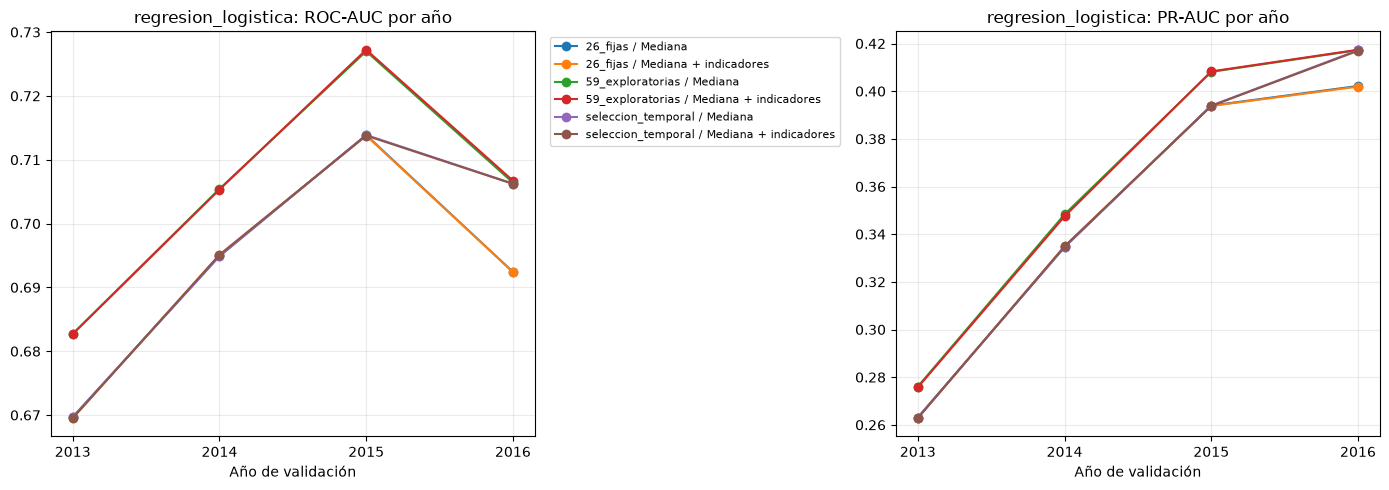

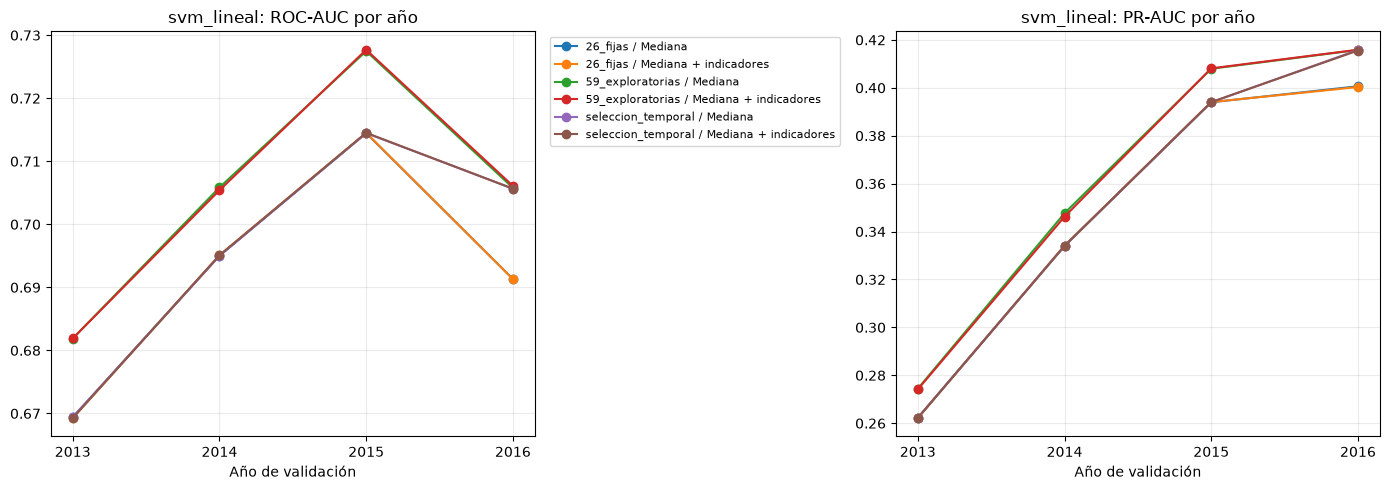

Resultados guardados en: C:\Users\josue\Proyecto-ML-Grupo8\outputs\comparacion_lineales
regresion_logistica / 26_fijas / Mediana + indicadores vs 26 mediana: ΔROC=-0.00002 en 1/4; ΔPR=-0.00008 en 1/4.
regresion_logistica / 59_exploratorias / Mediana vs 26 mediana: ΔROC=+0.01267 en 4/4; ΔPR=+0.01399 en 4/4.
regresion_logistica / 59_exploratorias / Mediana + indicadores vs 26 mediana: ΔROC=+0.01277 en 4/4; ΔPR=+0.01378 en 4/4.
regresion_logistica / seleccion_temporal / Mediana vs 26 mediana: ΔROC=+0.00346 en 1/4; ΔPR=+0.00375 en 1/4.
regresion_logistica / seleccion_temporal / Mediana + indicadores vs 26 mediana: ΔROC=+0.00343 en 2/4; ΔPR=+0.00368 en 2/4.
svm_lineal / 26_fijas / Mediana + indicadores vs 26 mediana: ΔROC=-0.00000 en 2/4; ΔPR=-0.00007 en 2/4.
svm_lineal / 59_exploratorias / Mediana vs 26 mediana: ΔROC=+0.01269 en 4/4; ΔPR=+0.01375 en 4/4.
svm_lineal / 59_exploratorias / Mediana + indicadores vs 26 mediana: ΔROC=+0.01272 en 4/4; ΔPR=+0.01337 en 4/4.
svm_lineal / seleccion_te

In [7]:
resultados=pd.DataFrame(resultados_filas)
cobertura_detalle=pd.concat(coberturas,ignore_index=True)
resumen=(resultados.groupby(["conjunto_variables","tipo_seleccion","modelo","tratamiento"],as_index=False)
 .agg(ROC_AUC_promedio=("ROC_AUC","mean"),ROC_AUC_desviacion=("ROC_AUC","std"),
      PR_AUC_promedio=("PR_AUC","mean"),PR_AUC_desviacion=("PR_AUC","std"),
      variables_min=("variables_originales","min"),variables_max=("variables_originales","max"),
      indicadores_promedio=("indicadores_faltantes","mean"),cortes_convergencia=("advertencia_convergencia","sum")))
resumen[["ROC_AUC_desviacion","PR_AUC_desviacion"]]=resumen[["ROC_AUC_desviacion","PR_AUC_desviacion"]].fillna(0)

# Diferencia contra 26 variables con mediana, por modelo.
difs=[]
for modelo in ["regresion_logistica","svm_lineal"]:
    baseline=resultados[(resultados.modelo==modelo)&(resultados.conjunto_variables=="26_fijas")&(resultados.tratamiento=="Mediana")]
    for conjunto in ["26_fijas","59_exploratorias","seleccion_temporal"]:
        for tratamiento in ["Mediana","Mediana + indicadores"]:
            actual=resultados[(resultados.modelo==modelo)&(resultados.conjunto_variables==conjunto)&(resultados.tratamiento==tratamiento)]
            if conjunto=="26_fijas" and tratamiento=="Mediana": continue
            m=baseline[["anio_validacion","ROC_AUC","PR_AUC"]].merge(actual[["anio_validacion","ROC_AUC","PR_AUC"]],on="anio_validacion",suffixes=("_base26_mediana","_actual"))
            difs.append({"modelo":modelo,"conjunto_variables":conjunto,"tratamiento":tratamiento,
                "delta_ROC_AUC_vs_26_mediana":float((m.ROC_AUC_actual-m.ROC_AUC_base26_mediana).mean()),
                "cortes_ROC_mayor_base":int((m.ROC_AUC_actual>m.ROC_AUC_base26_mediana).sum()),
                "delta_PR_AUC_vs_26_mediana":float((m.PR_AUC_actual-m.PR_AUC_base26_mediana).mean()),
                "cortes_PR_mayor_base":int((m.PR_AUC_actual>m.PR_AUC_base26_mediana).sum())})
diferencias=pd.DataFrame(difs)

# Diferencia de indicadores frente a mediana, emparejada en cada modelo y conjunto.
comparacion_ind=[]
for modelo in ["regresion_logistica","svm_lineal"]:
    for conjunto in ["26_fijas","59_exploratorias","seleccion_temporal"]:
        sin=resultados[(resultados.modelo==modelo)&(resultados.conjunto_variables==conjunto)&(resultados.tratamiento=="Mediana")]
        con=resultados[(resultados.modelo==modelo)&(resultados.conjunto_variables==conjunto)&(resultados.tratamiento=="Mediana + indicadores")]
        m=sin[["anio_validacion","ROC_AUC","PR_AUC"]].merge(con[["anio_validacion","ROC_AUC","PR_AUC"]],on="anio_validacion",suffixes=("_sin","_con"))
        comparacion_ind.append({"modelo":modelo,"conjunto_variables":conjunto,
          "delta_ROC_AUC_indicadores":float((m.ROC_AUC_con-m.ROC_AUC_sin).mean()),
          "cortes_ROC_mejora":int((m.ROC_AUC_con>m.ROC_AUC_sin).sum()),
          "delta_PR_AUC_indicadores":float((m.PR_AUC_con-m.PR_AUC_sin).mean()),
          "cortes_PR_mejora":int((m.PR_AUC_con>m.PR_AUC_sin).sum())})
indicadores_resumen=pd.DataFrame(comparacion_ind)

display(resumen.round(5))
display(diferencias.round(5))
display(indicadores_resumen.round(5))
display(resultados[["modelo","conjunto_variables","tratamiento","anio_validacion","variables_originales","indicadores_faltantes","ROC_AUC","PR_AUC","advertencia_convergencia"]].sort_values(["modelo","conjunto_variables","tratamiento","anio_validacion"]).round(5))

# Cobertura resumida y variables más incompletas en cada corte.
resumen_cobertura=(cobertura_detalle.groupby(["modelo","experimento","anio_validacion"],as_index=False)
 .agg(variables=("variable","count"),variables_con_faltantes=("faltante_pct_entrenamiento",lambda s:int((s>0).sum())),
      faltante_promedio_pct=("faltante_pct_entrenamiento","mean"),faltante_maximo_pct=("faltante_pct_entrenamiento","max"),
      indicadores=("indicador_creado","sum")))
display(resumen_cobertura.round(2))

# Figuras de métricas anuales: los fijos y temporales se grafican por separado.
for modelo in ["regresion_logistica","svm_lineal"]:
    fig,axes=plt.subplots(1,2,figsize=(14,5))
    subset=resultados[resultados.modelo==modelo]
    for conj in ["26_fijas","59_exploratorias","seleccion_temporal"]:
        for trat in ["Mediana","Mediana + indicadores"]:
            s=subset[(subset.conjunto_variables==conj)&(subset.tratamiento==trat)].sort_values("anio_validacion")
            label=f"{conj} / {trat}"
            axes[0].plot(s.anio_validacion,s.ROC_AUC,marker="o",label=label)
            axes[1].plot(s.anio_validacion,s.PR_AUC,marker="o",label=label)
    axes[0].set_title(f"{modelo}: ROC-AUC por año")
    axes[1].set_title(f"{modelo}: PR-AUC por año")
    for ax in axes:
        ax.set_xticks(ANIOS_VALIDACION); ax.set_xlabel("Año de validación"); ax.grid(alpha=.25)
    axes[0].legend(fontsize=8,bbox_to_anchor=(1.02,1),loc="upper left")
    fig.tight_layout(); display(fig); plt.close(fig)

salida=RAIZ/"outputs"/"comparacion_lineales"
salida.mkdir(parents=True,exist_ok=True)
resultados.to_csv(salida/"metricas_por_configuracion_y_anio.csv",index=False)
resumen.to_csv(salida/"resumen_promedios_y_variabilidad.csv",index=False)
diferencias.to_csv(salida/"diferencias_vs_baseline_26_mediana.csv",index=False)
indicadores_resumen.to_csv(salida/"diferencias_indicadores_vs_mediana.csv",index=False)
cobertura_detalle.to_csv(salida/"faltantes_por_variable_y_corte.csv",index=False)
resumen_cobertura.to_csv(salida/"resumen_cobertura_por_corte.csv",index=False)
pd.DataFrame({"variables_26":pd.Series(variables_26),"variables_59":pd.Series(variables_59),"candidatas":pd.Series(candidatas)}).to_csv(salida/"listas_variables.csv",index=False)
print("Resultados guardados en:",salida)

for _,r in diferencias.iterrows():
    print(f"{r['modelo']} / {r['conjunto_variables']} / {r['tratamiento']} vs 26 mediana: ΔROC={r['delta_ROC_AUC_vs_26_mediana']:+.5f} en {int(r['cortes_ROC_mayor_base'])}/4; ΔPR={r['delta_PR_AUC_vs_26_mediana']:+.5f} en {int(r['cortes_PR_mayor_base'])}/4.")


## 4. Lectura y recomendación

1. **Las 59 variables elevan las métricas de ambos modelos frente a 26, con mediana.** Regresión logística pasa de ROC-AUC 0.6927 / PR-AUC 0.3484 a 0.7054 / 0.3624. SVM pasa de 0.6926 / 0.3477 a 0.7052 / 0.3615. La mejora aparece en los cuatro años, pero es exploratoria: la lista de 59 se determinó con faltantes hasta 2016, incluyendo los años de validación.
2. **Los indicadores no aportan una mejora práctica.** Para los conjuntos fijos de 26, empeoran ligeramente ambas métricas en los dos modelos. Con 59, cambian ROC-AUC menos de 0.00011 en promedio y reducen PR-AUC en ambos modelos. Con selección temporal, también producen cambios prácticamente nulos o negativos.
3. **La selección temporal estricta mejora el promedio respecto a las 26 fijas, pero casi todo el cambio ocurre en 2016.** Regresión logística obtiene 0.6962 / 0.3522 y SVM 0.6961 / 0.3515. Ambos usan 26 variables en 2013–2015 y 57 en el corte de 2016. La mejora de promedio frente a 26 aparece en 1 de los 4 cortes; la variación entre años también aumenta.
4. **Los resultados exploratorios de 59 son mejores que la selección temporal estricta, pero no deben tomarse como una comparación final justa.** La lista de 59 se eligió conociendo el porcentaje de faltantes de los años de validación. No se usaron etiquetas de validación para esa selección, pero sí información de disponibilidad de esos años.
5. **Candidato para cada algoritmo:** mantener imputación por mediana sin indicadores. Para elegir variables en validación, usar el umbral de 10% calculado solo en cada entrenamiento. La selección temporal resulta preferible metodológicamente, aunque su ventaja promedio es modesta y depende del año final. Si se confirma esta estrategia, se puede volver a optimizar los hiperparámetros con ese preprocesamiento antes de elegir el modelo definitivo.

Las desviaciones entre años se incluyen en las tablas. No hubo advertencias de convergencia en ninguno de los 48 ajustes. Regresión logística se evaluó con `predict_proba`; SVM con `decision_function`. No se usaron datos desde 2017, calibración ni umbrales de clasificación. La conclusión es comparativa, no una afirmación de significancia estadística.

## Referencias

scikit-learn developers. (s. f.). *LogisticRegression*. scikit-learn API documentation. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

scikit-learn developers. (s. f.). *LinearSVC*. scikit-learn API documentation. https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html

scikit-learn developers. (s. f.). *Pipeline and composite estimators*. scikit-learn User Guide. https://scikit-learn.org/stable/modules/compose.html